# 02 · Average effects: difference in means, CUPED, Lin regression, AIPW; robustness; the observational counterfactual

Read with: [`03_ate_cuped_regression.md`](../docs/learn/03_ate_cuped_regression.md),
[`04_propensity_ipw_aipw.md`](../docs/learn/04_propensity_ipw_aipw.md).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from tierlift.config import REPO_ROOT, load_config
from tierlift.simulate import SimulatedData
cfg = load_config()
DATA, RESULTS, FIGS = REPO_ROOT / "data", REPO_ROOT / "results", REPO_ROOT / "reports" / "figures"
assert DATA.exists(), "run `make all` (or `tierlift run-all`) first: the notebooks read data/ and results/"
data = SimulatedData.load(DATA)
e, truth = data.experiment, data.truth.set_index("client_id")
primary, control = cfg.analysis.primary_contrast
def fig(name): display(Image(filename=str(FIGS / name), width=900))
print(f"seed {cfg.seed}, {len(e):,} clients, cells {cfg.experiment.cells}")

seed 13, 5,000 clients, cells {'holdout': 0.3, 'nudge': 0.3, 'incentive': 0.4}


## 1. Four estimators of the same ATE, per treatment cell

The truth column is the planted population effect on these clients.

In [2]:
from tierlift.experiment.ate import ate_table
from tierlift.features import build_features
tabs = {}
for cell in cfg.treatment_cells:
    s = e[e["cell"].isin([cell, control])].reset_index(drop=True); d = (s["cell"] == cell).to_numpy()
    tabs[cell] = ate_table(s["exp_revenue"].to_numpy(), d, s["pre_revenue"].to_numpy(), build_features(s), seed=cfg.seed)
    tt = truth.loc[s["client_id"]]
    print(f"{cell}: true relative effect {tt[f'revenue_{cell}'].sum() / tt['revenue_holdout'].sum() - 1:+.2%}")
    display(tabs[cell][["effect", "se", "rel_effect", "rel_ci_low", "rel_ci_high", "p_value", "variance_vs_dim"]])

nudge: true relative effect +2.79%


,effect,se,rel_effect,rel_ci_low,rel_ci_high,p_value,variance_vs_dim
estimator,,,,,,,
Difference in means,-550.7146,"2,657.7675",-0.0089,-0.0922,0.0745,0.8358,1.0000
CUPED,"-1,048.5625","1,762.4947",-0.0169,-0.0724,0.0387,0.5519,0.4398
Lin regression (HC2),-712.7828,"1,513.9706",-0.0114,-0.0587,0.0359,0.6378,0.3245
AIPW (cross-fitted GBM),935.4562,951.5944,0.0152,-0.0153,0.0457,0.3256,0.1282


incentive: true relative effect -3.04%


,effect,se,rel_effect,rel_ci_low,rel_ci_high,p_value,variance_vs_dim
estimator,,,,,,,
Difference in means,"-2,844.0282","2,537.9382",-0.0457,-0.1235,0.0321,0.2625,1.0000
CUPED,"-2,900.7397","1,767.1043",-0.0466,-0.1023,0.0090,0.1007,0.4848
Lin regression (HC2),"-1,716.1259","1,488.4150",-0.0279,-0.0745,0.0188,0.2489,0.3439
AIPW (cross-fitted GBM),"-2,124.9545",832.5186,-0.0343,-0.0601,-0.0084,0.0107,0.1076


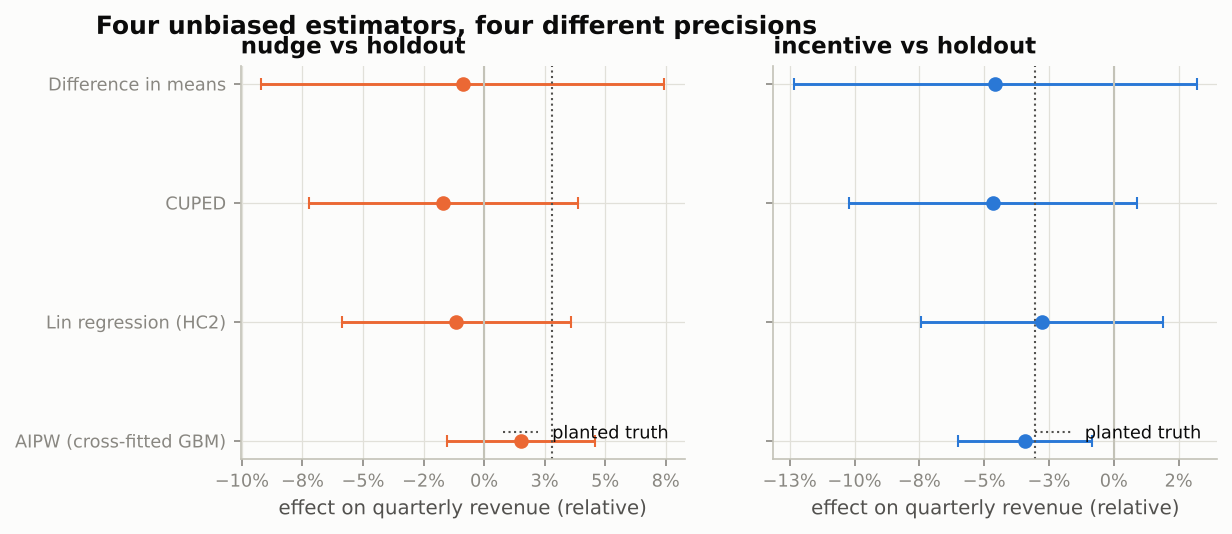

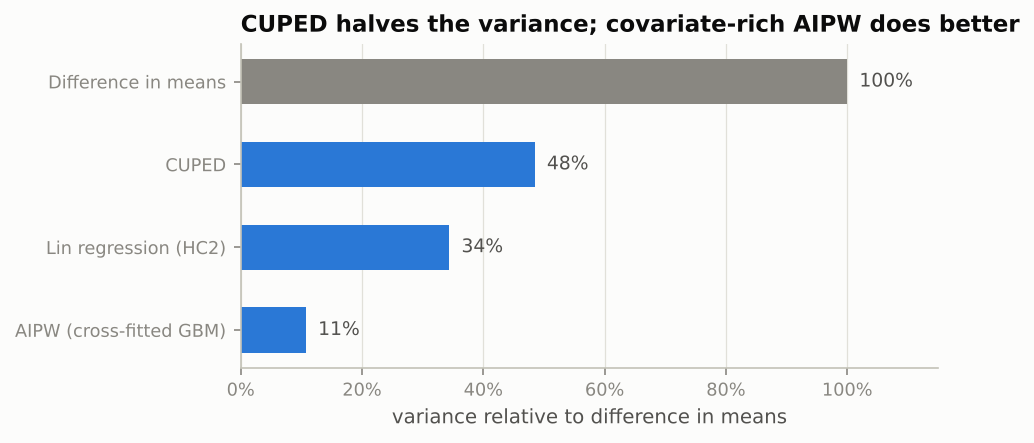

In [3]:
fig("01_ate_estimators.png"); fig("02_variance_reduction.png")

## 2. CUPED in one picture: the pre-period predicts the experiment period

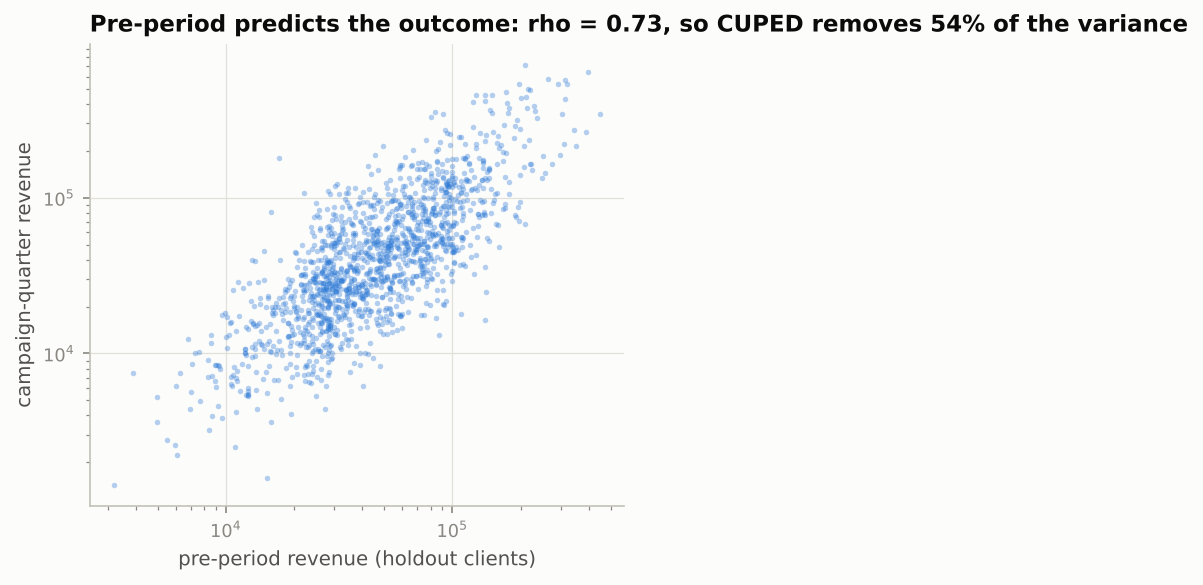

In [4]:
fig("03_cuped_scatter.png")

## 3. Robustness: Welch, Mann–Whitney, stratified permutation; Holm across cells

In [5]:
from tierlift.experiment.robustness import robustness_table, holm
s = e[e["cell"].isin([primary, control])].reset_index(drop=True); d = (s["cell"] == primary).to_numpy()
display(robustness_table(s["exp_revenue"].to_numpy(), d, s["stratum"].to_numpy(), n_permutations=2000, seed=cfg.seed))
p = {c: float(t.loc["CUPED", "p_value"]) for c, t in tabs.items()}
print("raw p:", p); print("Holm-adjusted:", holm(p))

,statistic,p_value,prob_superiority,null_sd
test,,,,
Welch t,-1.1206,0.2625,NaN,NaN
Mann-Whitney U,"1,477,139.0000",0.3965,0.4916,NaN
Permutation (stratified),"-2,844.0282",0.1454,NaN,"1,969.2749"


raw p: {'nudge': 0.5518896983692269, 'incentive': 0.10068920348220808}
Holm-adjusted: {'incentive': 0.20137840696441617, 'nudge': 0.5518896983692269}


## 4. What if we had not randomised?

Same potential outcomes; clients opt in as engaged, growing, near-tier clients would.

/home/claude/revenue-tier-and-churn-experiment/src/tierlift/experiment/ate.py:143: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit = sm.OLS(y, design[:, keep]).fit(cov_type="HC2")


,effect,se,true_ate,bias,covers_truth
estimator,,,,,
Naive difference in means,"24,587.7200","2,230.5685","-1,812.2343","26,399.9543",False
Regression adjustment (linear),"-3,898.4867","4,291.8384","-1,812.2343","-2,086.2524",True
IPW (logistic propensity),"10,904.3113","3,071.7847","-1,812.2343","12,716.5456",False
AIPW (cross-fitted),591.4229,479.5177,"-1,812.2343","2,403.6572",False


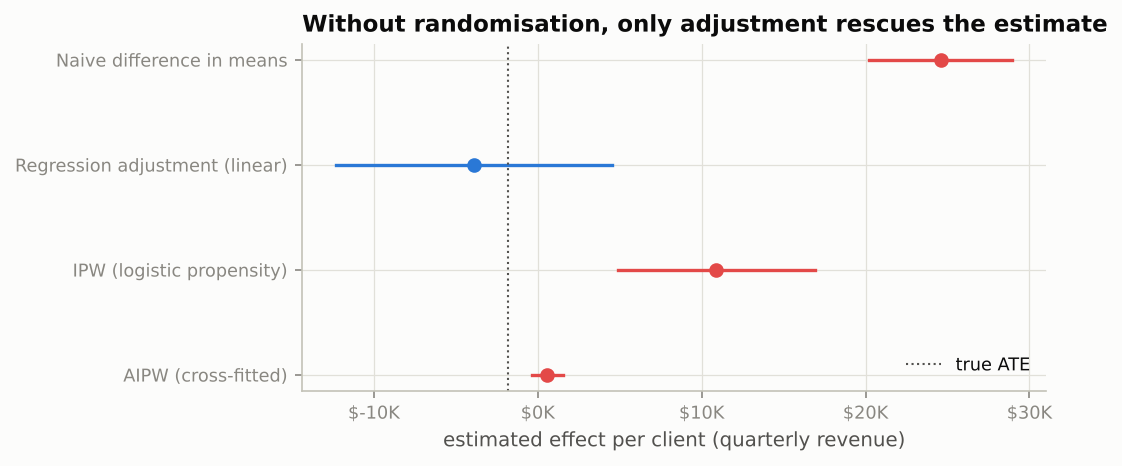

,mean_bias,rmse,mean_se,ci95_coverage,n_draws
estimator,,,,,
Naive difference in means,"16,185.1185","16,255.2735","2,256.1061",0.0000,10
Regression adjustment (linear),33.9072,"1,439.5652","1,543.0476",0.9000,10
IPW (logistic propensity),"1,336.7131","5,999.4503","5,126.2673",1.0000,10
AIPW (cross-fitted),-95.1739,"2,271.5929","1,383.8094",0.9000,10


In [6]:
from tierlift.experiment.observational import simulate_opt_in, observational_estimates
obs = simulate_opt_in(e, data.truth, seed=cfg.seed)
display(observational_estimates(obs, build_features(obs).to_numpy(), seed=cfg.seed)[["effect", "se", "true_ate", "bias", "covers_truth"]])
fig("04_observational_bias.png")
display(pd.read_csv(RESULTS / "observational_replication.csv", index_col=0))

## Check your understanding

1. CUPED's θ is ≈ 1.06. Explain in one sentence what "subtract 1.06 × (pre-revenue − mean)" does to a client whose pre-period revenue was unusually high.
2. The AIPW standard error is less than half of CUPED's. Which *extra* information does AIPW use that CUPED does not?
3. In the observational table the naive estimator is +48%. Which direction would the bias go if, instead, *shrinking* clients were the ones who opted in?